# 01 · Análisis exploratorio y preparación de datos

**Proyecto:** Detector de Fake News · Inteligencia Artificial (UCA, 2026)
**Entregable 3 del acta.** Este notebook *no* reimplementa lógica: importa todo del paquete `fakenews` (`src/fakenews/`), así lo que se ve acá es exactamente lo que usa el modelo.

Contenido:
1. Carga y validación del dataset principal (ISOT / *Fake and Real News Dataset*, Kaggle).
2. Calidad de datos: faltantes, vacíos, atípicos, duplicados (lab 03).
3. Distribución de clases, temas (`subject`) y fechas.
4. Largos de texto por clase.
5. Auditoría de fuga: marcas de fuente/formato que separan las clases sin leer el contenido.
6. Limpieza: qué se quita y qué queda.
7. Preparación final: filas perdidas por paso, splits y chequeo de solapamiento.
8. Palabras más frecuentes por clase (tras limpiar) y ejemplos.

> Requiere haber corrido `make data` (descarga + preparación + auditoría).

In [1]:
import re, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

from fakenews.config import get_paths, load_config, read_json
from fakenews.data import load_isot
from fakenews.cleaning import build_document, clean_text, rule_names, word_count
from fakenews.splits import load_split
from fakenews.audit import marker_table
from fakenews import plots

pd.set_option("display.max_colwidth", 120)
paths, cfg = get_paths(), load_config()
print("Semilla:", cfg["seed"])

Semilla: 42


## 1. Carga y validación
`load_isot` valida columnas esperadas y tipos, y asigna Falsa = 1 (clase positiva) y Real = 0.

In [2]:
raw = load_isot()
print(raw.shape)
display(raw.groupby("label").size().rename({0: "real", 1: "falsa"}).to_frame("filas"))
raw.head(3)

(44898, 7)


,filas
label,
real,21417
falsa,23481


,id,label,title,text,subject,date,source_file
0,fake_00000,1,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,"Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout...",News,"December 31, 2017",Fake.csv
1,fake_00001,1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,"House Intelligence Committee Chairman Devin Nunes is going to have a bad day. He s been under the assumption, like m...",News,"December 31, 2017",Fake.csv
2,fake_00002,1,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,"On Friday, it was revealed that former Milwaukee Sheriff David Clarke, who was being considered for Homeland Securit...",News,"December 30, 2017",Fake.csv


## 2. Calidad de datos (faltantes, vacíos, atípicos, duplicados)

In [3]:
quality = read_json(paths.reports / "data_audit.json")
rows = []
for cls in ("falsas", "reales"):
    q = quality[cls]
    rows.append({"clase": cls, "filas": q["filas"], "texto vacío": q["texto_vacio_o_solo_espacios"],
                 "< 20 palabras": q["texto_menos_de_20_palabras"], "solo enlaces": q["texto_solo_enlaces"],
                 "fechas no parseables": q["fechas_no_parseables"], "> 5000 palabras": q["textos_mas_de_5000_palabras"],
                 "dup. exactos (texto)": q["duplicados_exactos_texto"], "rango de fechas": " a ".join(q["rango_fechas"])})
pd.DataFrame(rows).set_index("clase")

,filas,texto vacío,< 20 palabras,solo enlaces,fechas no parseables,> 5000 palabras,dup. exactos (texto),rango de fechas
clase,,,,,,,,
falsas,23481,630,1105,84,10,28,6026,2015-03-31 a 2018-02-19
reales,21417,1,1,0,0,1,225,2016-01-13 a 2017-12-31


In [4]:
print("Ejemplos de fechas no parseables (falsas):", quality["falsas"]["ejemplos_fechas_no_parseables"])
print("Textos idénticos entre clases:", quality["textos_identicos_entre_clases"])

Ejemplos de fechas no parseables (falsas): ['https://100percentfedup.com/served-roy-moore-vietnamletter-veteran-sets-record-straight-honorable-decent-respectable-patriotic-commander-soldier/', 'https://100percentfedup.com/video-hillary-asked-about-trump-i-just-want-to-eat-some-pie/', 'https://100percentfedup.com/12-yr-old-black-conservative-whose-video-to-obama-went-viral-do-you-really-love-america-receives-death-threats-from-left/']
Textos idénticos entre clases: 0


**Lectura.** Casi todos los textos vacíos o muy cortos son falsas (son noticias de las que solo quedó el título), y las falsas tienen muchos más duplicados exactos. Si no se filtran antes de dividir, el modelo aprende que "texto vacío ⇒ falsa" y los duplicados filtran de train a test.

## 3. Clases, temas (`subject`) y fechas

In [5]:
ct = pd.crosstab(raw["subject"], raw["label"].map({0: "real", 1: "falsa"}))
ct

label,falsa,real
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145


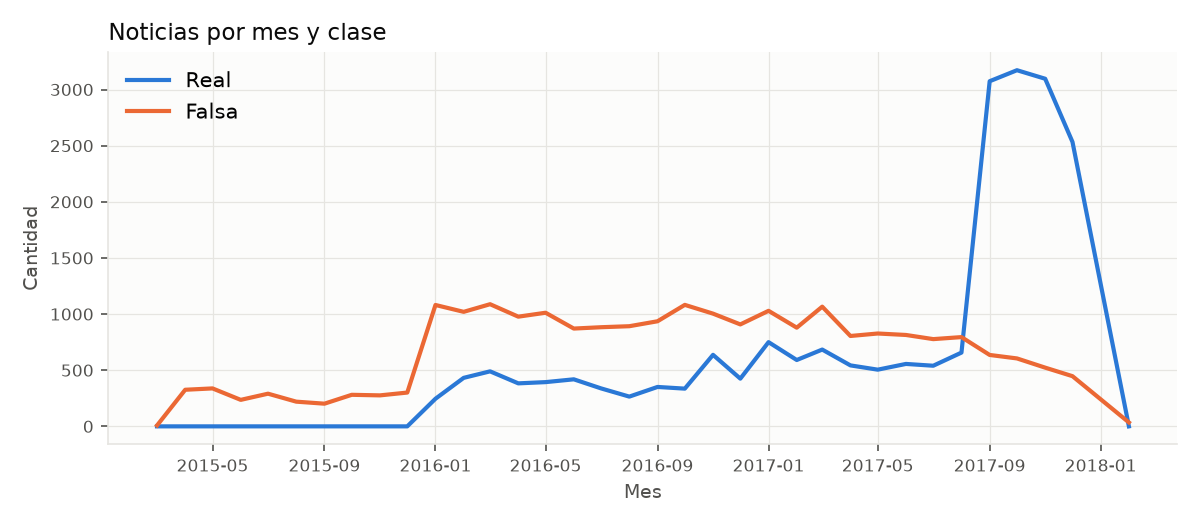

In [6]:
dates = pd.to_datetime(raw["date"].str.strip(), errors="coerce", format="mixed")
per_month = (raw.assign(mes=dates.dt.to_period("M")).dropna(subset=["mes"])
             .groupby(["mes", "label"]).size().unstack(fill_value=0).rename(columns={0: "real", 1: "falsa"}))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(per_month.index.to_timestamp(), per_month["real"], color=plots.REAL, lw=2, label="Real")
ax.plot(per_month.index.to_timestamp(), per_month["falsa"], color=plots.FAKE, lw=2, label="Falsa")
plots._style(ax, "Noticias por mes y clase", "Mes", "Cantidad"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(paths.figures / "eda_por_mes.png", dpi=150); plt.close(fig)
display(Image(paths.figures / "eda_por_mes.png"))

**Lectura.** Los `subject` de cada clase son **disjuntos** (`politicsNews`/`worldnews` solo en reales; `News`, `politics`, `left-news`, etc. solo en falsas): esa columna sola clasifica perfecto. Las fechas también difieren en rango y hasta en *formato* del string. Por eso **ni `subject` ni `date` se usan como entrada** (el acta pide solo texto).

## 4. Largo de los textos

,count,mean,std,min,1%,50%,99%,max
label,,,,,,,,
falsa,23481.0,436.0,421.0,0.0,0.0,375.0,1975.0,8375.0
real,21417.0,394.0,281.0,0.0,44.0,367.0,1179.0,5292.0


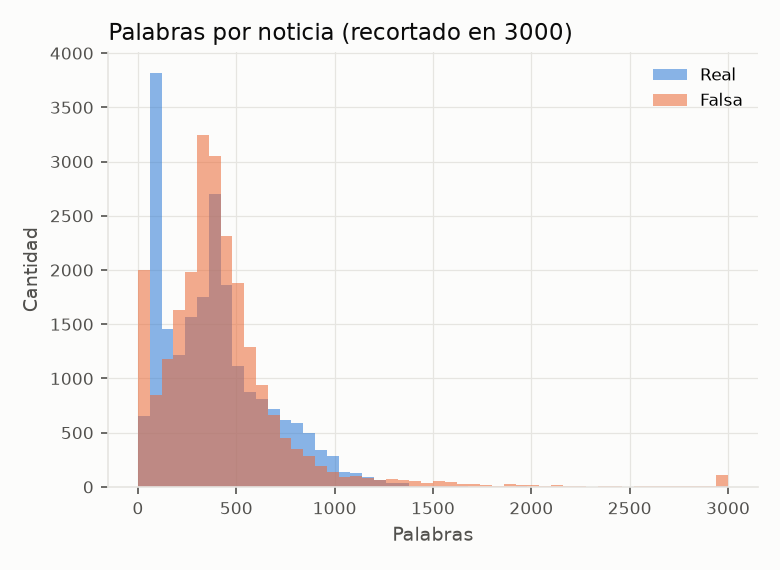

In [7]:
raw["palabras"] = raw["text"].map(word_count)
display(raw.groupby(raw["label"].map({0: "real", 1: "falsa"}))["palabras"].describe(percentiles=[.01, .5, .99]).round(0))
plots.hist_by_class({"Real": raw.loc[raw.label == 0, "palabras"].clip(upper=3000),
                     "Falsa": raw.loc[raw.label == 1, "palabras"].clip(upper=3000)},
                    "Palabras por noticia (recortado en 3000)", "Palabras", paths.figures / "eda_largos.png")
display(Image(paths.figures / "eda_largos.png"))

## 5. Auditoría de fuga
Para cada marca se mide qué fracción de cada clase la contiene y la accuracy de una regla que usa **solo** esa marca. La tabla completa está en `reports/leakage_audit.json`.

In [8]:
leak = read_json(paths.reports / "leakage_audit.json")
before = pd.DataFrame(leak["marcas_texto_crudo"]).set_index("marca")
after = pd.DataFrame(leak["marcas_tras_limpieza_full"]).set_index("marca")
tab = before[["frac_falsas", "frac_reales", "accuracy_regla_sola"]].join(
    after[["frac_falsas", "frac_reales"]], rsuffix="_tras_limpiar")
tab.sort_values("accuracy_regla_sola", ascending=False)

/var/folders/fz/3b9pfx890xv5kf9_0xbbzr9w0000gn/T/ipykernel_3137/2333801323.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  tab = before[["frac_falsas", "frac_reales", "accuracy_regla_sola"]].join(


,frac_falsas,frac_reales,accuracy_regla_sola,frac_falsas_tras_limpiar,frac_reales_tras_limpiar
marca,,,,,
dateline '(Reuters) -',0.0000,0.9920,0.9962,0.0000,0.0000
palabra 'Reuters',0.0126,0.9982,0.9925,0.0000,0.0000
título con palabra en MAYÚSCULAS (>=4 letras),0.7959,0.0250,0.8814,0.6669,0.0259
apóstrofo convertido en espacio ('don t'),0.6541,0.0889,0.7766,0.6602,0.2510
comilla/apóstrofo curvo (’ “ ”),0.0000,0.5051,0.7639,0.0000,0.0000
'Featured image',0.3476,0.0000,0.6588,0.0000,0.0000
@usuario,0.2606,0.0131,0.6070,0.0000,0.0000
"firma de tuit '(@x) Mes D, AAAA'",0.2320,0.0000,0.5984,0.0000,0.0000
título con (VIDEO)/[VIDEO],0.2154,0.0000,0.5897,0.0000,0.0000


In [9]:
pd.DataFrame({k: v["accuracy_val"] for k, v in leak["metadatos_solos"].items()}, index=["accuracy en validación"]).T

,accuracy en validación
solo_subject,1.0000
"solo_fecha (año, mes, día)",0.7197
"solo_formato_de_fecha (espacio final, mes abreviado)",1.0000


**Hallazgos de fuga (medidos, no supuestos):**
- El *dateline* `CIUDAD (Reuters) -` aparece en ~99 % de las reales y en ninguna falsa: una regla con esa sola marca acierta ~99,6 %.
- La **codificación tipográfica** difiere por fuente: las reales usan comillas y apóstrofos curvos (`’ “ ”`) y en las falsas el apóstrofo quedó reemplazado por un espacio (`don t`, `Trump s`). Esto no estaba en la lista inicial de hipótesis y se descubrió explorando.
- Créditos de imagen (`Featured image via…`, `Getty Images`), embeds de tuits, `pic.twitter.com`, URLs, `Via:`/`Read more:` y promos de sitios aparecen solo en falsas.
- Los títulos falsos tienen palabras en MAYÚSCULAS ~80 % de las veces contra ~2,5 % de los reales, y etiquetas `(VIDEO)`.
- `subject` y el formato de `date` separan las clases al 100 %.

## 6. Limpieza
Una sola función (`fakenews.cleaning.clean_text`), la misma en entrenamiento e inferencia. Reglas, en orden:

In [10]:
print(rule_names())
ej = raw[raw.label == 0].iloc[0]
print("CRUDO :", (ej["title"] + " | " + ej["text"])[:300])
print("LIMPIO:", build_document(ej["title"], ej["text"])[:300].replace("\n", " | "))
ej = raw[(raw.label == 1) & raw.text.str.contains("Featured image")].iloc[0]
print("CRUDO :", ej["text"][-250:])
print("LIMPIO:", build_document(ej["title"], ej["text"])[-250:])

['html_tag', 'agency_dateline', 'agency_correction', 'reuters_template', 'reuters_template_tail', 'sponsor_disclaimer', 'daily_highlights', 'reuters_tweet_stamp', 'agency_name', 'pic_twitter', 'tweet_signature', 'url', 'domain', 'handle', 'featured_image', 'photo_credit', 'getty', 'via_line', 'read_more', 'site_promo', 'media_tag', 'media_prefix', 'video_embed', 'agency_title_prefix', 'quotes', 'control_chars', 'orphan_dashes']
CRUDO : As U.S. budget fight looms, Republicans flip their fiscal script | WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged
LIMPIO: As U.S. budget fight looms, Republicans flip their fiscal script | The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a fiscal conserva

Tras limpiar, las marcas de la tabla de arriba quedan en 0 % en ambas clases (columnas `_tras_limpiar`). Lo que **sigue distinguiendo** a las clases es estilo: mayúsculas en títulos, signos `!`, y el uso de contracciones informales (`don t`) que es más frecuente en los blogs. Eso no se borra: es parte del texto, pero se declara como limitación (el modelo aprende en parte "estilo agencia vs. estilo blog").

## 7. Preparación final: filas perdidas por paso y splits

In [11]:
manifest = read_json(paths.reports / "splits_manifest.json")
pasos = []
for p in manifest["pasos"]:
    if "filas_eliminadas" in p:
        pasos.append({"paso": p["paso"], "eliminadas": p["filas_eliminadas"],
                      "reales": p["eliminadas_por_clase"]["real"], "falsas": p["eliminadas_por_clase"]["fake"],
                      "grupos en conflicto": p.get("grupos_con_etiquetas_en_conflicto", "")})
    else:
        pasos.append({"paso": p["paso"], "eliminadas": "", "reales": p["filas"]["real"], "falsas": p["filas"]["fake"]})
pd.DataFrame(pasos)

,paso,eliminadas,reales,falsas,grupos en conflicto
0,carga,,21417,23481,NaN
1,filtrar_textos_cortos (< 20 palabras tras limpiar),729,3,726,
2,duplicados_exactos (texto limpio normalizado),5871,490,5381,0
3,casi_duplicados (Jaccard >= 0.8 en shingles de 5 palabras),99,40,59,1
4,dataset_final,,20884,17315,NaN


In [12]:
display(pd.DataFrame(manifest["splits"]).T[["real", "fake", "total"]])
print("Solapamiento entre splits:", json.dumps(manifest["solapamiento"], ensure_ascii=False))

,real,fake,total
train,14619,12120,26739
val,3133,2597,5730
test,3132,2598,5730


Solapamiento entre splits: {"train-val": {"ids": 0, "exactos": 0, "casi_duplicados": 0}, "train-test": {"ids": 0, "exactos": 0, "casi_duplicados": 0}, "val-test": {"ids": 0, "exactos": 0, "casi_duplicados": 0}, "ok": true}


**Lectura.** Tras deduplicar, la clase mayoritaria pasa a ser **real** (~54,6 %): el clasificador trivial tiene ~0,55 de accuracy y F1 de falsa = 0. La división 70/15/15 es estratificada con semilla 42 y no hay solapamiento exacto ni casi-duplicado (MinHash, Jaccard ≥ 0,8) entre splits.

## 8. Palabras más frecuentes por clase (texto limpio, solo train)

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
train = load_split("train")
cv = CountVectorizer(stop_words="english", min_df=5, max_features=20000)
X = cv.fit_transform(train["doc"])
terms = cv.get_feature_names_out()
rows = {}
for lab, name in ((0, "real"), (1, "falsa")):
    freq = np.asarray(X[train["label"].to_numpy() == lab].sum(axis=0)).ravel()
    rows[name] = [terms[i] for i in np.argsort(-freq)[:25]]
pd.DataFrame(rows)

,real,falsa
0,said,trump
1,trump,said
2,president,people
3,state,president
4,government,just
5,house,donald
6,republican,like
7,new,obama
8,states,clinton
9,people,hillary


In [14]:
# Términos con mayor diferencia de frecuencia relativa entre clases (log-ratio con suavizado)
fr = np.asarray(X[train["label"].to_numpy() == 1].sum(0)).ravel() + 1
re_ = np.asarray(X[train["label"].to_numpy() == 0].sum(0)).ravel() + 1
lr = np.log((fr / fr.sum()) / (re_ / re_.sum()))
pd.DataFrame({"más típicos de falsas": [terms[i] for i in np.argsort(-lr)[:20]],
              "más típicos de reales": [terms[i] for i in np.argsort(lr)[:20]]})

,más típicos de falsas,más típicos de reales
0,js,myanmar
1,var,rohingya
2,fjs,rakhine
3,antifa,puigdemont
4,cking,fdp
5,cdata,hariri
6,hilariously,zuma
7,finicum,suu
8,bundy,kyi
9,ck,odinga


**Lectura.** En las reales dominan marcas del estilo de agencia (`said`, días de la semana, cargos y títulos formales); en las falsas, vocabulario de opinión y de redes. El modelo puede apoyarse en estas diferencias de **estilo de fuente** más que en la veracidad: es el riesgo principal del acta, y se mide con el experimento controlado y la validación externa en LIAR (ver `docs/informe_resultados.md`).

In [15]:
ejemplos = pd.concat([train[train.label == 0].sample(2, random_state=1), train[train.label == 1].sample(2, random_state=1)])
ejemplos.assign(clase=ejemplos["label"].map({0: "real", 1: "falsa"}), inicio=ejemplos["doc"].str[:200])[["clase", "inicio"]]

,clase,inicio
24597,real,Hungary PM warns against eroding free movement for EU citizens\nHungarian Prime Minister Viktor Orban said Europe mu...
22950,real,Spain issues arrest warrant for ousted Catalan leader\nSpain on Friday issued an arrest warrant on sedition and othe...
8203,falsa,"CAMELOT COMES TO DC...First Lady, Trump Women Stun Viewers\nTHE VICE PRESIDENT AND HIS WIFE KAREN CAME OUT TO DANCE ..."
35,falsa,Trump Gets An Epic F**ck You From Britain Over His White Supremacist Retweets\nDonald Trump has a white supremacy pr...
